In [1]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../data/311.db")

def q(sql):
    return pd.read_sql(sql, conn)

In [2]:
q("SELECT COUNT(*) AS total_rows FROM requests_raw")

,total_rows
0,2427812


In [3]:
q("SELECT agency, COUNT(*) AS total_rows FROM requests_raw GROUP BY agency")

,agency,total_rows
0,DOT,398753
1,DSNY,608185
2,HPD,1420874


In [4]:
q("""SELECT substr(created_date,1,7) AS month, agency, COUNT(*) AS total_rows
     FROM requests_raw GROUP BY month, agency ORDER BY month, agency""")

,month,agency,total_rows
0,2023-01,DOT,19133
1,2023-01,DSNY,20353
2,2023-01,HPD,64620
3,2023-02,DOT,17523
4,2023-02,DSNY,17388
...,...,...,...
67,2024-11,DSNY,23156
68,2024-11,HPD,74911
69,2024-12,DOT,16131
70,2024-12,DSNY,22461


In [5]:
q("SELECT * FROM requests_raw LIMIT 5")

,unique_key,created_date,closed_date,agency,complaint_type,descriptor,borough,status,incident_zip
0,56408061,2023-01-01T00:32:00.000,2023-01-01T01:30:00.000,DOT,Traffic Signal Condition,Controller,BROOKLYN,Closed,NaN
1,56409451,2023-01-01T00:18:00.000,2023-01-01T03:40:00.000,DOT,Traffic Signal Condition,Controller,BROOKLYN,Closed,11208
2,56410624,2023-01-01T00:25:00.000,2023-01-01T05:50:00.000,DOT,Traffic Signal Condition,Controller,QUEENS,Closed,11358
3,56410653,2023-01-01T00:52:00.000,2023-01-01T03:50:00.000,DOT,Traffic Signal Condition,Controller,QUEENS,Closed,11102
4,56411233,2023-01-01T00:18:00.000,2023-01-01T03:40:00.000,DOT,Traffic Signal Condition,Controller,BROOKLYN,Closed,11208


In [6]:
q("""SELECT agency,
            SUM(closed_date IS NULL OR closed_date = '') AS never_closed,
            COUNT(*) AS total_rows
     FROM requests_raw GROUP BY agency""")

,agency,never_closed,total_rows
0,DOT,5331,398753
1,DSNY,3041,608185
2,HPD,7093,1420874


In [7]:
q("""SELECT substr(created_date,1,7) AS month, COUNT(*) AS total_rows
     FROM requests_raw
     WHERE agency = 'HPD' AND substr(created_date,1,7) IN ('2023-11','2023-12','2024-11','2024-12')
     GROUP BY month ORDER BY month""")

,month,total_rows
0,2023-11,86767
1,2023-12,74880
2,2024-11,74911
3,2024-12,102690


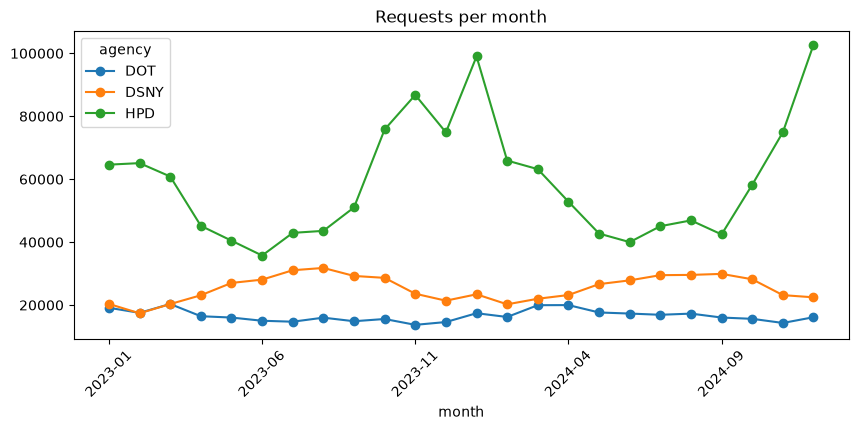

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

m = q("""SELECT substr(created_date,1,7) AS month, agency, COUNT(*) AS total_rows
         FROM requests_raw GROUP BY month, agency ORDER BY month""")

m["month"] = pd.PeriodIndex(m["month"], freq="M")
month_range = pd.period_range(start=m["month"].min(), end=m["month"].max(), freq="M")

p = (
    m.pivot(index="month", columns="agency", values="total_rows")
     .reindex(month_range, fill_value=0)
)
p.index = p.index.astype(str)

p.plot(figsize=(12, 4), marker="o")
plt.title("Requests per month")
plt.xlabel("Month")
plt.ylabel("Requests")
plt.xticks(rotation=45)
plt.show()